<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/4_fields_particles/solitons/soliton_ch01_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*TASI Lectures on Solitons* — `soliton_ch01_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# Solitons Ch 1 · Instantons — Figure Notebook
Based on D. Tong, TASI Lectures on Solitons

In [1]:
# ── Setup ─────────────────────────────────────────────────────────────
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch
from mpl_toolkits.mplot3d import Axes3D  # noqa
import os

BG   = '#1e1e2e'; FG = '#cdd6f4'; EDGE = '#45475a'
AMB  = '#e8a838'; YELL = '#f9c74f'; GREEN = '#90ee90'
RED  = '#e07070'; PURP = '#c792ea'; BLUE = '#89c4f4'; TEAL = '#2ec4b6'

plt.rcParams.update({
    'figure.facecolor': BG, 'axes.facecolor': BG,
    'text.color': FG, 'axes.labelcolor': FG,
    'xtick.color': FG, 'ytick.color': FG,
    'axes.edgecolor': EDGE, 'grid.color': EDGE, 'grid.alpha': 0.25,
    'font.size': 12, 'axes.titlesize': 13, 'axes.titleweight': 'bold',
    'axes.titlecolor': AMB, 'legend.framealpha': 0.3,
    'legend.edgecolor': EDGE, 'lines.linewidth': 2.2,
    'axes.linewidth': 1.2, 'figure.dpi': 110,
})

CH = 'ch01'
os.makedirs(f'figures/{CH}', exist_ok=True)

def save(name, fig):
    fig.savefig(f'figures/{CH}/{name}', dpi=150, bbox_inches='tight', facecolor=BG)
    plt.show()
    print(f'Saved: figures/{CH}/{name}')

print('Setup complete.')


Setup complete.


## Fig 01 · Soliton Hierarchy Web

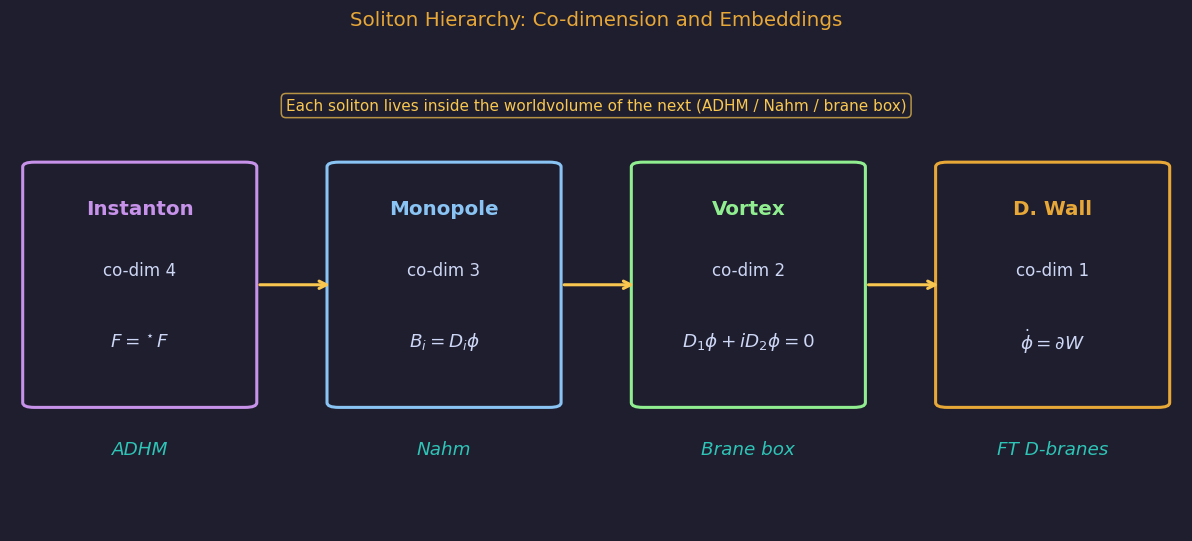

Saved: figures/ch01/fig01_soliton_web.png


In [2]:
# ── fig01: soliton hierarchy web ─────────────────────────────────────────
fig, ax = plt.subplots(figsize=(11, 5))
fig.suptitle("Soliton Hierarchy: Co-dimension and Embeddings", color=AMB, fontsize=13)
ax.set_facecolor(BG); ax.axis('off')

solitons = [
    (0.12, 0.52, "Instanton", "co-dim 4", r"$F={}^\star F$",       PURP),
    (0.38, 0.52, "Monopole",  "co-dim 3", r"$B_i=D_i\phi$",        BLUE),
    (0.64, 0.52, "Vortex",    "co-dim 2", r"$D_1\phi+iD_2\phi=0$", GREEN),
    (0.90, 0.52, "D. Wall",   "co-dim 1", r"$\dot\phi=\partial W$", AMB),
]
for (x, y, name, codim, eqn, col) in solitons:
    rect = FancyBboxPatch((x-0.10, y-0.25), 0.18, 0.50,
                          boxstyle="round,pad=0.01", lw=2,
                          edgecolor=col, facecolor=BG, transform=ax.transAxes, zorder=3)
    ax.add_patch(rect)
    ax.text(x-0.01, y+0.16, name,  ha='center', va='center', fontsize=13,
            fontweight='bold', color=col, transform=ax.transAxes)
    ax.text(x-0.01, y+0.03, codim, ha='center', va='center', fontsize=11,
            color=FG, transform=ax.transAxes)
    ax.text(x-0.01, y-0.12, eqn,  ha='center', va='center', fontsize=12,
            color=FG, transform=ax.transAxes)

for x0, x1 in [(0.22, 0.28), (0.48, 0.54), (0.74, 0.80)]:
    ax.annotate('', xy=(x1-0.005, 0.52), xytext=(x0-0.01, 0.52),
                xycoords='axes fraction', textcoords='axes fraction',
                arrowprops=dict(arrowstyle='->', color=YELL, lw=2.0))

ax.text(0.50, 0.90, "Each soliton lives inside the worldvolume of the next (ADHM / Nahm / brane box)",
        ha='center', va='center', fontsize=10, color=YELL, transform=ax.transAxes,
        bbox=dict(boxstyle='round,pad=0.3', fc=BG, ec=YELL, alpha=0.7))

labels = ["ADHM", "Nahm", "Brane box", "FT D-branes"]
for x, lbl in zip([0.12, 0.38, 0.64, 0.90], labels):
    ax.text(x-0.01, 0.17, lbl, ha='center', va='center', fontsize=12,
            color=TEAL, transform=ax.transAxes, style='italic')

plt.tight_layout()
save('fig01_soliton_web.png', fig)


## Fig 02 · BPST Instanton Action Density

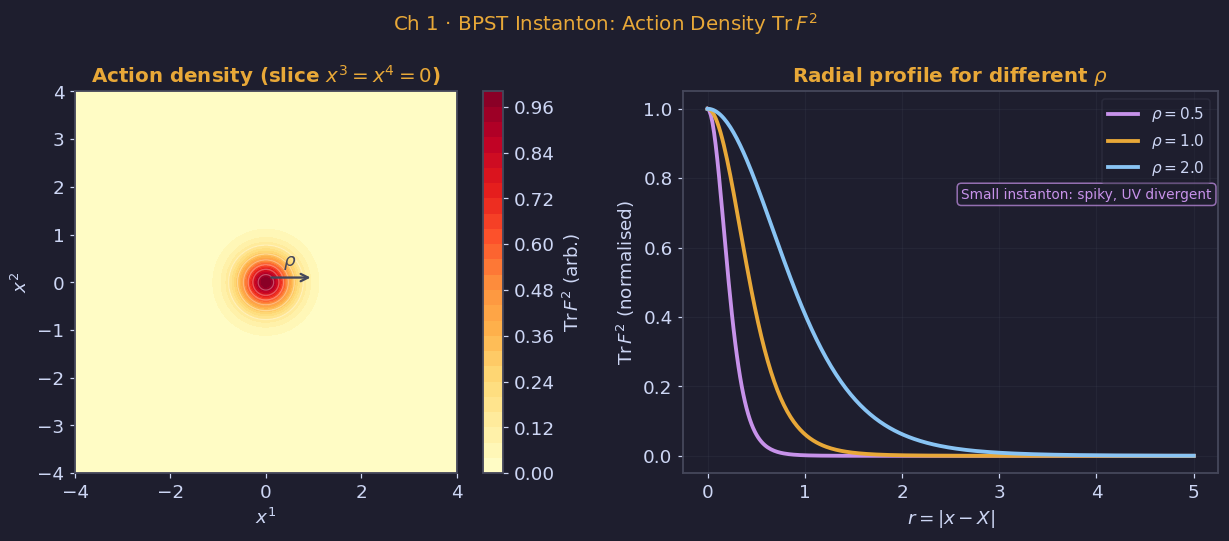

Saved: figures/ch01/fig02_instanton_profile.png


In [3]:
# ── fig02: BPST instanton action density ─────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle(r"Ch 1 · BPST Instanton: Action Density $\mathrm{Tr}\,F^2$", color=AMB, fontsize=13)

x = np.linspace(-4, 4, 200); y = np.linspace(-4, 4, 200)
X, Y = np.meshgrid(x, y)
rho = 1.0; r2 = X**2 + Y**2
action = rho**4 / (r2 + rho**2)**4

ax = axes[0]; ax.set_facecolor(BG)
ax.set_title(r"Action density (slice $x^3=x^4=0$)", color=AMB)
cf = ax.contourf(X, Y, action, levels=30, cmap='YlOrRd')
plt.colorbar(cf, ax=ax, label=r'$\mathrm{Tr}\,F^2$ (arb.)')
ax.contour(X, Y, action, levels=8, colors='white', alpha=0.3, linewidths=0.8)
ax.set_xlabel(r'$x^1$'); ax.set_ylabel(r'$x^2$'); ax.set_aspect('equal')
ax.annotate('', xy=(rho, 0.1), xytext=(0.05, 0.1),
            arrowprops=dict(arrowstyle='->', color=EDGE, lw=1.5))
ax.text(rho/2, 0.35, r'$\rho$', ha='center', color=EDGE, fontsize=12)

ax2 = axes[1]; ax2.set_facecolor(BG)
ax2.set_title(r"Radial profile for different $\rho$", color=AMB)
r = np.linspace(0, 5, 300)
for rho_val, col, lbl in [(0.5, PURP, r'$\rho=0.5$'), (1.0, AMB, r'$\rho=1.0$'),
                           (2.0, BLUE, r'$\rho=2.0$')]:
    prof = rho_val**4 / (r**2 + rho_val**2)**4
    ax2.plot(r, prof/prof.max(), color=col, lw=2.5, label=lbl)
ax2.set_xlabel(r'$r = |x - X|$'); ax2.set_ylabel(r'$\mathrm{Tr}\,F^2$ (normalised)')
ax2.legend(fontsize=10); ax2.grid(True, alpha=0.2)
ax2.text(0.52, 0.72, "Small instanton: spiky, UV divergent",
         transform=ax2.transAxes, fontsize=9, color=PURP,
         bbox=dict(boxstyle='round', fc=BG, ec=PURP, alpha=0.7))

plt.tight_layout()
save('fig02_instanton_profile.png', fig)


## Fig 03 · ADHM D-brane Construction

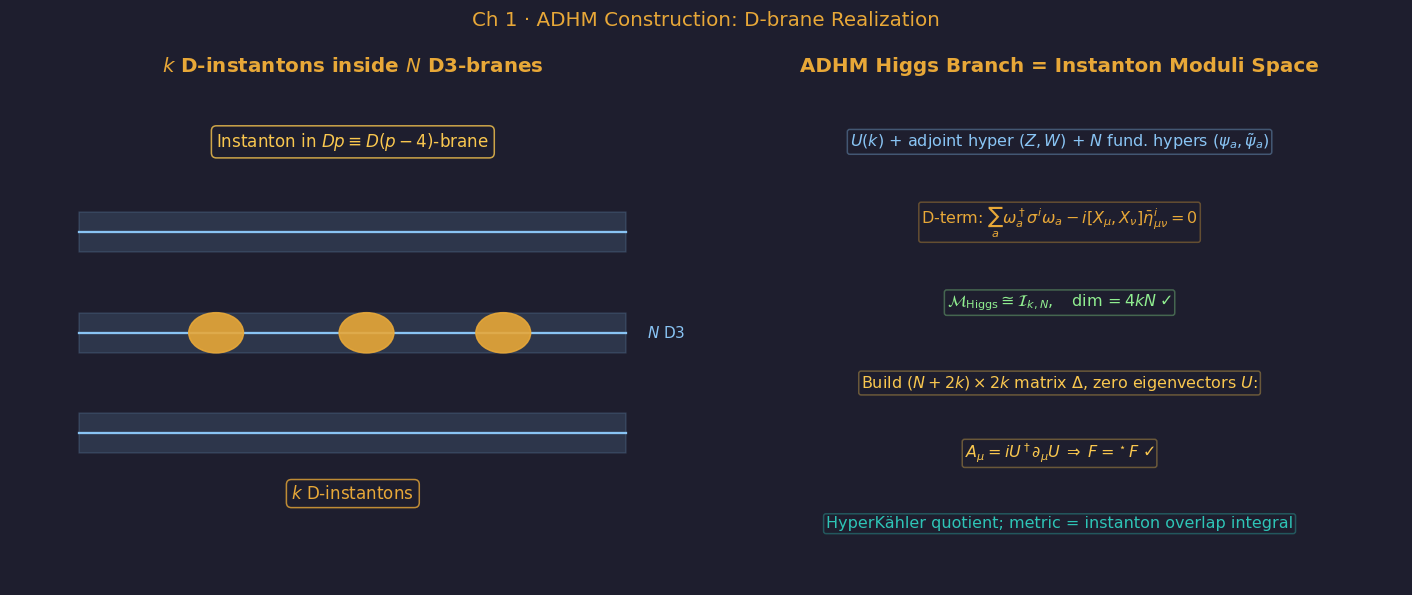

Saved: figures/ch01/fig03_adhm_brane.png


In [4]:
# ── fig03: ADHM D-brane construction schematic ───────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
fig.suptitle(r"Ch 1 · ADHM Construction: D-brane Realization", color=AMB, fontsize=13)

ax = axes[0]; ax.set_facecolor(BG); ax.axis('off')
ax.set_title(r"$k$ D-instantons inside $N$ D3-branes", color=AMB)
for y in np.linspace(0.30, 0.70, 3):
    ax.fill_between([0.10, 0.90], [y-0.04, y-0.04], [y+0.04, y+0.04],
                    color=BLUE, alpha=0.15, transform=ax.transAxes)
    ax.plot([0.10, 0.90], [y, y], color=BLUE, lw=1.5, transform=ax.transAxes)
ax.text(0.93, 0.50, r'$N$ D3', ha='left', va='center', fontsize=10,
        color=BLUE, transform=ax.transAxes)
for xc in [0.30, 0.52, 0.72]:
    c = plt.Circle((xc, 0.50), 0.04, color=AMB, alpha=0.9,
                   transform=ax.transAxes, zorder=5)
    ax.add_patch(c)
ax.text(0.50, 0.18, r'$k$ D-instantons', ha='center', va='center',
        fontsize=11, color=AMB, transform=ax.transAxes,
        bbox=dict(boxstyle='round', fc=BG, ec=AMB, alpha=0.8))
ax.text(0.50, 0.88, r'Instanton in $Dp \equiv D(p-4)$-brane',
        ha='center', va='center', fontsize=11, color=YELL, transform=ax.transAxes,
        bbox=dict(boxstyle='round', fc=BG, ec=YELL, alpha=0.8))

ax2 = axes[1]; ax2.set_facecolor(BG); ax2.axis('off')
ax2.set_title("ADHM Higgs Branch = Instanton Moduli Space", color=AMB)
items = [
    (0.50, 0.88, r'$U(k)$ + adjoint hyper $(Z,W)$ + $N$ fund. hypers $(\psi_a,\tilde\psi_a)$', BLUE),
    (0.50, 0.72, r'D-term: $\sum_a\omega_a^\dagger\sigma^i\omega_a - i[X_\mu,X_\nu]\bar\eta^i_{\mu\nu}=0$', AMB),
    (0.50, 0.56, r'$\mathcal{M}_{\rm Higgs}\cong\mathcal{I}_{k,N},\quad\dim=4kN\;\checkmark$', GREEN),
    (0.50, 0.40, r'Build $(N+2k)\times 2k$ matrix $\Delta$, zero eigenvectors $U$:', YELL),
    (0.50, 0.26, r'$A_\mu = iU^\dagger\partial_\mu U \;\Rightarrow\; F={}^\star F\;\checkmark$', YELL),
    (0.50, 0.12, r'HyperKähler quotient; metric = instanton overlap integral', TEAL),
]
for (x, y, txt, col) in items:
    ax2.text(x, y, txt, ha='center', va='center', fontsize=10.5,
             color=col, transform=ax2.transAxes,
             bbox=dict(boxstyle='round,pad=0.15', fc=BG, ec=col, alpha=0.35))
plt.tight_layout()
save('fig03_adhm_brane.png', fig)


## Fig 04 · Instantons and AdS₅

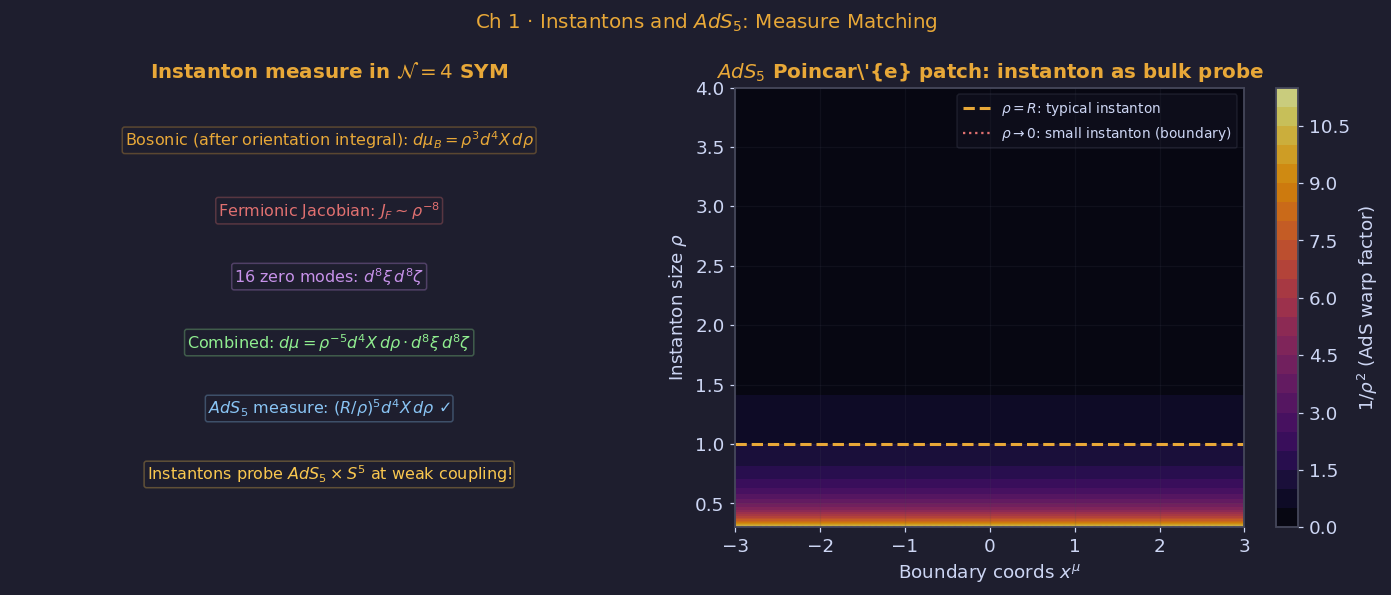

Saved: figures/ch01/fig04_ads5_instanton.png


In [5]:
# ── fig04: instanton measure → AdS5 geometry ─────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
fig.suptitle(r"Ch 1 · Instantons and $AdS_5$: Measure Matching", color=AMB, fontsize=13)

ax = axes[0]; ax.set_facecolor(BG); ax.axis('off')
ax.set_title(r"Instanton measure in $\mathcal{N}=4$ SYM", color=AMB)
steps = [
    (0.50, 0.88, r'Bosonic (after orientation integral): $d\mu_B = \rho^3 d^4X\,d\rho$', AMB),
    (0.50, 0.72, r'Fermionic Jacobian: $J_F \sim \rho^{-8}$', RED),
    (0.50, 0.57, r'16 zero modes: $d^8\xi\,d^8\zeta$', PURP),
    (0.50, 0.42, r'Combined: $d\mu = \rho^{-5}d^4X\,d\rho \cdot d^8\xi\,d^8\zeta$', GREEN),
    (0.50, 0.27, r'$AdS_5$ measure: $(R/\rho)^5 d^4X\,d\rho$ $\checkmark$', BLUE),
    (0.50, 0.12, r'Instantons probe $AdS_5\times S^5$ at weak coupling!', YELL),
]
for (x, y, txt, col) in steps:
    ax.text(x, y, txt, ha='center', va='center', fontsize=10.5,
            color=col, transform=ax.transAxes,
            bbox=dict(boxstyle='round,pad=0.15', fc=BG, ec=col, alpha=0.30))

ax2 = axes[1]; ax2.set_facecolor(BG)
ax2.set_title(r"$AdS_5$ Poincar\'{e} patch: instanton as bulk probe", color=AMB)
rho_vals = np.linspace(0.3, 4.0, 300)
x4_vals  = np.linspace(-3, 3, 300)
RHO, X4 = np.meshgrid(rho_vals, x4_vals)
cf = ax2.contourf(X4, RHO, 1.0/RHO**2, levels=25, cmap='inferno', alpha=0.8)
plt.colorbar(cf, ax=ax2, label=r'$1/\rho^2$ (AdS warp factor)')
ax2.axhline(1.0, color=AMB, ls='--', lw=2.0, label=r'$\rho=R$: typical instanton')
ax2.axhline(0.3, color=RED,  ls=':', lw=1.5, label=r'$\rho\to 0$: small instanton (boundary)')
ax2.set_xlabel(r'Boundary coords $x^\mu$')
ax2.set_ylabel(r'Instanton size $\rho$')
ax2.set_ylim(0.3, 4.0); ax2.legend(fontsize=9); ax2.grid(True, alpha=0.15)
plt.tight_layout()
save('fig04_ads5_instanton.png', fig)


## Download

In [6]:
# ── Download figures as zip ─────────────────────────────────────────────
import shutil
CH = 'ch01'
shutil.make_archive(f'{CH}_figures', 'zip', f'figures/{CH}')
try:
    from google.colab import files
    files.download(f'{CH}_figures.zip')
except ImportError:
    print(f'Not in Colab — saved to figures/{CH}/')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>